# Numerical Laplace Transform Code for Dielectric Spectroscopy

This file tests code used to numerically transform a frequency space dielectric function to the time domain response expected after a step down edge of a square wave. 

This file tests the code for a simple RC capacitor, a debye model and a Cole-Cole function
 capacitor, Debye, and Cole–Cole


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import epsilon_0

from py_dielectric_spectroscopy.transform_dielectric_data import (
    constant_capacitance,
    debye_capacitance,
    cole_cole_capacitance,
    RC_divider_transfer,
    square_wave_voltage_response,
)

In [17]:
R = 1e5              # ohm
C0 = 200e-12         # F, empty cell
tau_d = 3e-3         # s
alpha = 0.8
epsilon_s = 50.0     # static permittivity
epsilon_inf = 2.0    # infinite-frequency permittivity
Delta_k = epsilon_s - epsilon_inf
rho = 1e10           # sample resistivity (ohm m)

V_low, V_high = 0.0, 3.0

T = 0.03             # full square-wave period (s)
N = 10000            # samples in one half-period
t_half = np.arange(N) * (T / (2 * N))
dt = t_half[1] - t_half[0]

print(f"RC0 = {R*C0:.2g} s; half-period = {T/2*1e3:g} ms; dt = {dt*1e6:g} us")

RC0 = 2e-05 s; half-period = 15 ms; dt = 1.5 us


## Run the same numerical transform for all three models

The Fourier convention used in the package gives an input of **0 V in the first half-period**, followed by **3 V in the second half-period**. We calculate the first half and reconstruct the second by antisymmetry about the circuit's DC output.

For the ordinary capacitor, $H(0)=1$. For the dielectric models with DC resistivity $\rho$, $H(0)=1/[1+RC_0/(\rho\epsilon_0)]$.

In [18]:
models = {
    "Capacitor": (
        constant_capacitance,
        dict(C0=C0 * epsilon_s),
        1.0
    ),
    "Debye": (
        debye_capacitance,
        dict(C0=C0, k_inf=epsilon_inf,
             Delta_k=Delta_k, tau=tau_d, rho=rho),
        1 / (1 + R*C0/(rho*epsilon_0))
    ),
    "Cole–Cole": (
        cole_cole_capacitance,
        dict(C0=C0, k_inf=epsilon_inf,
             Delta_k=Delta_k, tau=tau_d,
             alpha=alpha, rho=rho),
        1 / (1 + R*C0/(rho*epsilon_0))
    ),
}

responses = {}

for label, (cap_func, cap_params, H_dc) in models.items():
    responses[label] = square_wave_voltage_response(
        t_half,
        RC_divider_transfer,
        dc_gain=H_dc,
        V_high=3.0,
        V_low=0.0,
        R=R,
        capacitance_function=cap_func,
        **cap_params
    )

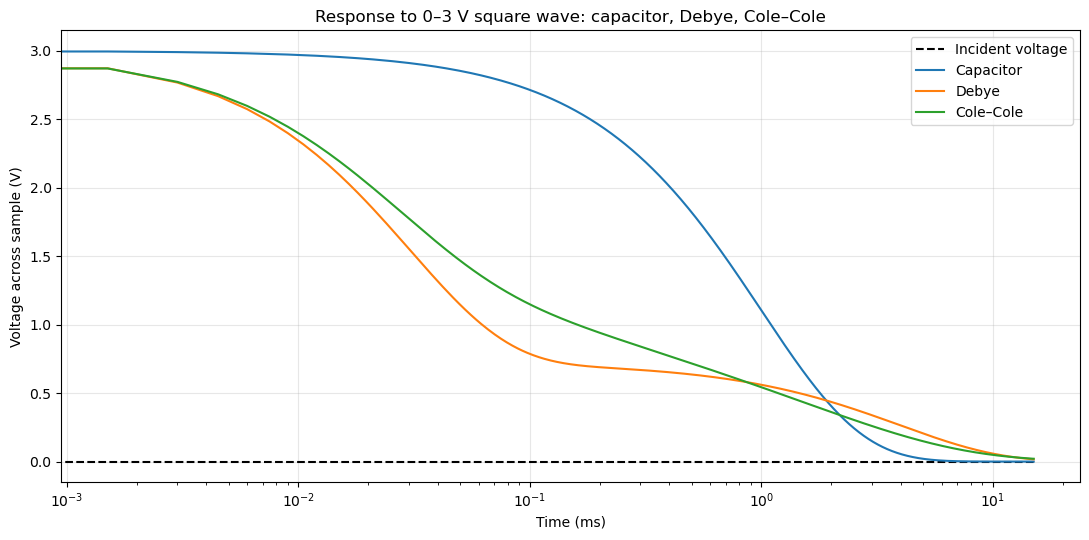

In [19]:
fig, ax = plt.subplots(figsize=(11, 5.5))
t_input = np.array([-0.005, 0, t_half[-1]])
input_voltage = np.array([3.0, 0.0, 0.0])
ax.step(t_input * 1e3, input_voltage,
        where="post", color="black",
        linestyle="--", label="Incident voltage")
for label, voltage in responses.items():
    ax.plot(t_half * 1e3, voltage, label=label)

ax.set(xlabel="Time (ms)", ylabel="Voltage across sample (V)",
       title="Response to 0–3 V square wave: capacitor, Debye, Cole–Cole")
ax.grid(True, alpha=0.3)
ax.legend()
plt.xscale('log')
plt.tight_layout()
plt.show()